# Universidad Nacional de San Antonio Abad del Cusco
# PREPROCESAMIENTO DE IMÁGENES DEL DATASET HAM10000

**Tema:** Análisis y preprocesamiento de imágenes dermatoscópicas para la clasificación de lesiones cutáneas.

**Integrantes:**
- Jesus Augusto Alegria Mendoza - 215780
- Brandon Ccoyo Mejia - 210923
- Gustavo Pantoja Olave - 210939

**Curso:** VISIÓN COMPUTACIONAL  
**Docente:** HANS HARLEY CCACYAHUILLCA BEJAR

## Índice

0. Entorno y rutas
1. Copia local e inventario de imágenes
2. Exploración de metadatos (clases, edad, sexo, localización, tipo de diagnóstico)
3. Estructura por lesión (por qué importa para la partición)
4. Inspección visual y validación de calidad
5. Pipeline de preprocesamiento: demostración paso a paso
6. Ejecución del preprocesamiento sobre todo el dataset
7. Resultados del preprocesamiento
8. Casi-duplicados y grupos
9. Partición train / val / test sin fuga de datos
10. Estadísticas de entrenamiento y manejo del desbalance
11. Aumento de datos
12. Exportación y resumen de la ejecución

## 0. Entorno y rutas

**Antes de ejecutar:**
1. Este notebook es **autosuficiente**: el código de apoyo se escribe solo en la sección 0 (celdas `%%writefile`). No hay que subir nada más.
2. La carpeta del dataset `Proyecto_V-C_HAM10000` pertenece a otra cuenta. Si no la ves en *Mi unidad*, ábrela en Drive → *Compartido conmigo* → clic derecho → **Organizar → Agregar acceso directo a Drive**.
3. Si `drive.mount` falla con *credential propagation was unsuccessful*: acepta la ventana emergente de permisos con la misma cuenta que tiene la carpeta, o ejecuta *Entorno de ejecución → Desconectar y eliminar entorno* y reintenta.

In [ ]:
!pip -q install opencv-python-headless imagehash "albumentations>=1.4,<3" seaborn tqdm scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 7.5 MB/s eta 0:00:00


In [ ]:
from google.colab import drive
drive.mount("/content/drive", force_remount=False)

Mounted at /content/drive


Las siguientes celdas escriben en el disco de Colab los módulos de apoyo (`hamvc`): preprocesamiento, partición sin fuga, estadísticas, aumento de datos y dataset de PyTorch. Se dejan visibles para poder explicarlos y modificarlos.

In [ ]:
import os
os.makedirs("/content/hamvc_code/hamvc", exist_ok=True)   # %%writefile no crea carpetas

In [ ]:
%%writefile /content/hamvc_code/hamvc/__init__.py
from .config import CLASSES, CLASS_NAMES_ES, PreprocConfig

Overwriting /content/hamvc_code/hamvc/__init__.py


In [ ]:
%%writefile /content/hamvc_code/hamvc/config.py
"""Constantes y parámetros del preprocesamiento."""

from dataclasses import dataclass

# Orden fijo de clases: el índice de cada clase es su etiqueta numérica.
CLASSES = ["akiec", "bcc", "bkl", "df", "mel", "nv", "vasc"]

CLASS_NAMES_ES = {
    "akiec": "Queratosis actínica / Bowen (akiec)",
    "bcc": "Carcinoma basocelular (bcc)",
    "bkl": "Lesión queratósica benigna (bkl)",
    "df": "Dermatofibroma (df)",
    "mel": "Melanoma (mel)",
    "nv": "Nevus melanocítico (nv)",
    "vasc": "Lesión vascular (vasc)",
}


@dataclass(frozen=True)
class PreprocConfig:
    """Parámetros del pipeline. Todo lo que cambie el resultado vive aquí."""

    img_size: int = 256            # lado de la imagen guardada (cuadrada)
    square_mode: str = "center_crop"  # "center_crop" | "pad" (sin deformar la imagen)
    crop_borders: bool = True      # recortar viñeteado / bordes negros
    border_thr: int = 20           # umbral de gris para considerar "negro"
    remove_hair: bool = True       # DullRazor: blackhat + inpainting
    hair_kernel: int = 17
    hair_thr: int = 10
    hair_max_frac: float = 0.20    # si la máscara cubre más, no se aplica (evita borrar lesión)
    inpaint_radius: int = 3
    color_constancy: bool = True   # Shades of Gray
    sog_power: int = 6
    out_ext: str = ".jpg"          # ".jpg" (liviano) o ".png" (sin pérdidas)
    jpg_quality: int = 95
    seed: int = 42

Overwriting /content/hamvc_code/hamvc/config.py


In [ ]:
%%writefile /content/hamvc_code/hamvc/io_utils.py
"""Copia local del dataset e inventario imagen <-> metadatos."""

from __future__ import annotations

import shutil
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import pandas as pd

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}


def list_images(root) -> list[Path]:
    return sorted(p for p in Path(root).rglob("*")
                  if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS)


def copy_images_local(src_root, dst_dir, workers: int = 16, progress=True) -> list[Path]:
    """Copia todas las imágenes de src_root a dst_dir (disco local de Colab).

    Leer 10 mil archivos desde Drive es lento; se copian una sola vez y el resto del
    flujo trabaja sobre el disco local. Es reanudable: no recopia lo que ya existe.
    """
    dst_dir = Path(dst_dir)
    dst_dir.mkdir(parents=True, exist_ok=True)
    srcs = list_images(src_root)

    def _copy(p: Path):
        d = dst_dir / p.name
        if d.exists() and d.stat().st_size == p.stat().st_size:
            return d
        shutil.copy2(p, d)
        return d

    with ThreadPoolExecutor(max_workers=workers) as ex:
        it = ex.map(_copy, srcs)
        if progress:
            from tqdm.auto import tqdm
            it = tqdm(it, total=len(srcs), desc="Copiando a disco local")
        return list(it)


def build_inventory(metadata: pd.DataFrame, image_dir) -> tuple[pd.DataFrame, dict]:
    """Une metadatos con archivos. Devuelve (df con image_path, informe)."""
    paths = list_images(image_dir)
    by_stem: dict[str, list[Path]] = {}
    for p in paths:
        by_stem.setdefault(p.stem, []).append(p)

    collisions = {k: v for k, v in by_stem.items() if len(v) > 1}
    df = metadata.copy()
    df["image_id"] = df["image_id"].astype(str)
    df["image_path"] = df["image_id"].map(lambda i: str(by_stem[i][0]) if i in by_stem else None)

    meta_ids = set(df["image_id"])
    report = {
        "archivos_de_imagen": len(paths),
        "ids_unicos_en_archivos": len(by_stem),
        "colisiones_de_nombre": len(collisions),
        "filas_de_metadatos": len(df),
        "metadatos_con_imagen": int(df["image_path"].notna().sum()),
        "metadatos_sin_imagen": int(df["image_path"].isna().sum()),
        "imagenes_sin_metadatos": len(set(by_stem) - meta_ids),
    }
    return df, report

Overwriting /content/hamvc_code/hamvc/io_utils.py


In [ ]:
%%writefile /content/hamvc_code/hamvc/preprocess.py
"""Pasos de preprocesamiento para imágenes dermatoscópicas.

Orden del pipeline (importa):
    1. recorte de bordes negros   -> antes de estimar color, para no sesgarlo
    2. eliminación de vello       -> a resolución original, donde el vello es más nítido
    3. constancia de color        -> Shades of Gray
    4. cuadrado + redimensión     -> sin deformar la proporción 4:3
"""

from __future__ import annotations

import json
from concurrent.futures import ProcessPoolExecutor
from pathlib import Path

import cv2
import numpy as np
import pandas as pd

from .config import PreprocConfig

cv2.setNumThreads(1)  # evita competir con los procesos paralelos


# --------------------------------------------------------------------------- #
# Pasos individuales (cada uno recibe y devuelve RGB uint8)
# --------------------------------------------------------------------------- #
def read_rgb(path) -> np.ndarray:
    """Lee y decodifica la imagen completa. Lanza OSError si está dañada."""
    bgr = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if bgr is None or bgr.size == 0:
        raise OSError(f"No se pudo decodificar: {path}")
    return cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)


def crop_black_borders(img: np.ndarray, thr: int = 20, min_keep: float = 0.6):
    """Recorta el marco negro del dermatoscopio. Devuelve (img, fue_recortada)."""
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    mask = (gray > thr).astype(np.uint8)
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, np.ones((5, 5), np.uint8))
    ys, xs = np.where(mask > 0)
    if len(ys) == 0:
        return img, False
    y0, y1, x0, x1 = ys.min(), ys.max() + 1, xs.min(), xs.max() + 1
    frac = (y1 - y0) * (x1 - x0) / (img.shape[0] * img.shape[1])
    # Si casi no hay borde, o el recorte sería exagerado, se deja la imagen intacta.
    if frac > 0.98 or frac < min_keep:
        return img, False
    return img[y0:y1, x0:x1], True


def hair_mask(img: np.ndarray, kernel: int = 17, thr: int = 10) -> np.ndarray:
    """Máscara de vello (estilo DullRazor): blackhat morfológico + umbral."""
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    se = cv2.getStructuringElement(cv2.MORPH_RECT, (kernel, kernel))
    bh = cv2.morphologyEx(gray, cv2.MORPH_BLACKHAT, se)
    bh = cv2.GaussianBlur(bh, (3, 3), 0)
    _, mask = cv2.threshold(bh, thr, 255, cv2.THRESH_BINARY)
    return cv2.dilate(mask, np.ones((3, 3), np.uint8))


def remove_hair(img: np.ndarray, kernel=17, thr=10, max_frac=0.20, radius=3):
    """Elimina vello por inpainting. Devuelve (img, fracción_de_máscara, aplicado)."""
    mask = hair_mask(img, kernel, thr)
    frac = float((mask > 0).mean())
    if frac == 0 or frac > max_frac:
        return img, frac, False
    return cv2.inpaint(img, mask, radius, cv2.INPAINT_TELEA), frac, True


def shades_of_gray(img: np.ndarray, p: int = 6) -> np.ndarray:
    """Constancia de color Shades of Gray (norma de Minkowski de orden p)."""
    x = img.astype(np.float32)
    illum = np.power(np.mean(np.power(x, p), axis=(0, 1)), 1.0 / p)
    illum = illum / (np.linalg.norm(illum) + 1e-6)
    out = x / (illum * np.sqrt(3.0) + 1e-6)
    return np.clip(out, 0, 255).astype(np.uint8)


def to_square(img: np.ndarray, size: int, mode: str = "center_crop") -> np.ndarray:
    """Convierte a cuadrado SIN deformar y redimensiona a size x size."""
    h, w = img.shape[:2]
    if mode == "center_crop":
        s = min(h, w)
        y, x = (h - s) // 2, (w - s) // 2
        img = img[y:y + s, x:x + s]
    elif mode == "pad":
        s = max(h, w)
        top, left = (s - h) // 2, (s - w) // 2
        img = cv2.copyMakeBorder(img, top, s - h - top, left, s - w - left,
                                 cv2.BORDER_CONSTANT, value=(0, 0, 0))
    else:
        raise ValueError(f"square_mode desconocido: {mode}")
    interp = cv2.INTER_AREA if img.shape[0] > size else cv2.INTER_CUBIC
    return cv2.resize(img, (size, size), interpolation=interp)


# --------------------------------------------------------------------------- #
# Pipeline completo para una imagen
# --------------------------------------------------------------------------- #
def process_array(img: np.ndarray, cfg: PreprocConfig):
    """Aplica el pipeline a un arreglo RGB. Devuelve (imagen_final, info)."""
    info = {"orig_w": int(img.shape[1]), "orig_h": int(img.shape[0])}

    if cfg.crop_borders:
        img, info["border_cropped"] = crop_black_borders(img, cfg.border_thr)
    else:
        info["border_cropped"] = False

    if cfg.remove_hair:
        img, info["hair_fraction"], info["hair_removed"] = remove_hair(
            img, cfg.hair_kernel, cfg.hair_thr, cfg.hair_max_frac, cfg.inpaint_radius)
    else:
        info["hair_fraction"], info["hair_removed"] = 0.0, False

    if cfg.color_constancy:
        img = shades_of_gray(img, cfg.sog_power)

    img = to_square(img, cfg.img_size, cfg.square_mode)
    return img, info


def image_stats(img: np.ndarray) -> dict:
    """Estadísticas por imagen para calcular media/desv. y analizar por clase."""
    x = img.astype(np.float64) / 255.0
    m = x.mean(axis=(0, 1))
    m2 = (x ** 2).mean(axis=(0, 1))
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    return {
        "mean_r": m[0], "mean_g": m[1], "mean_b": m[2],
        "meansq_r": m2[0], "meansq_g": m2[1], "meansq_b": m2[2],
        "brightness": float(gray.mean()),
        "sharpness": float(cv2.Laplacian(gray, cv2.CV_64F).var()),
    }


def phash_hex(img: np.ndarray) -> str:
    import imagehash
    from PIL import Image
    return str(imagehash.phash(Image.fromarray(img), hash_size=8))


def _worker(args):
    image_id, src, dst, cfg = args
    try:
        img = read_rgb(src)
        out, info = process_array(img, cfg)
        params = [cv2.IMWRITE_JPEG_QUALITY, cfg.jpg_quality] if cfg.out_ext == ".jpg" else []
        if not cv2.imwrite(str(dst), cv2.cvtColor(out, cv2.COLOR_RGB2BGR), params):
            raise OSError(f"No se pudo escribir {dst}")
        row = {"image_id": image_id, "ok": True, **info, **image_stats(out),
               "phash": phash_hex(out)}
        return row
    except Exception as exc:  # se registra y se sigue
        return {"image_id": image_id, "ok": False, "error": repr(exc)}


def run_preprocessing(df: pd.DataFrame, out_dir, cfg: PreprocConfig,
                      workers: int = 2, log_path=None, progress=True) -> pd.DataFrame:
    """Procesa todas las imágenes en paralelo y de forma reanudable.

    df necesita las columnas: image_id, image_path.
    Cada resultado se agrega a un .jsonl; si la sesión de Colab se cae, al volver a
    ejecutar solo se procesan las imágenes que faltan.
    """
    out_dir = Path(out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)
    log_path = Path(log_path or out_dir.parent / "preproc_log.jsonl")

    done = {}
    if log_path.exists():
        for line in log_path.read_text().splitlines():
            r = json.loads(line)
            if r.get("ok") and (out_dir / f"{r['image_id']}{cfg.out_ext}").exists():
                done[r["image_id"]] = r

    todo = [(r.image_id, r.image_path, out_dir / f"{r.image_id}{cfg.out_ext}", cfg)
            for r in df.itertuples() if r.image_id not in done]
    print(f"Ya procesadas: {len(done):,} | pendientes: {len(todo):,}")

    results = list(done.values())
    if todo:
        it = None
        with open(log_path, "a") as fh, ProcessPoolExecutor(max_workers=workers) as ex:
            it = ex.map(_worker, todo, chunksize=16)
            if progress:
                from tqdm.auto import tqdm
                it = tqdm(it, total=len(todo), desc="Preprocesando")
            for r in it:
                fh.write(json.dumps(r, default=float) + "\n")
                results.append(r)
    return pd.DataFrame(results)

Overwriting /content/hamvc_code/hamvc/preprocess.py


In [ ]:
%%writefile /content/hamvc_code/hamvc/split.py
"""Particiones train/val/test sin fuga de datos.

HAM10000 tiene ~10 015 imágenes pero solo ~7 470 lesiones: una misma lesión aparece en
varias fotos. Si se divide al azar por imagen, la misma lesión cae en train y en test y
las métricas salen infladas. Aquí se agrupa por lesión (y además por casi-duplicados
detectados con hash perceptual) y se estratifica por clase.
"""

from __future__ import annotations

import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedGroupKFold


# ------------------------------ casi-duplicados ----------------------------- #
_POPCOUNT = np.array([bin(i).count("1") for i in range(256)], dtype=np.uint8)


def near_duplicate_pairs(hashes: list[str], max_dist: int = 4, chunk: int = 500):
    """Pares (i, j, distancia) con distancia de Hamming <= max_dist (i < j)."""
    h = np.array([int(x, 16) for x in hashes], dtype=np.uint64)
    pairs = []
    for start in range(0, len(h), chunk):
        block = h[start:start + chunk]
        x = np.bitwise_xor(block[:, None], h[None, :])
        d = _POPCOUNT[x.view(np.uint8).reshape(*x.shape, 8)].sum(axis=-1)
        ii, jj = np.where(d <= max_dist)
        for a, b in zip(ii, jj):
            i = start + a
            if i < b:
                pairs.append((int(i), int(b), int(d[a, b])))
    return pairs


def build_groups(df: pd.DataFrame, pairs, lesion_col="lesion_id") -> pd.Series:
    """group_id = componentes conexas de (misma lesión) U (casi-duplicado)."""
    n = len(df)
    parent = list(range(n))

    def find(a):
        while parent[a] != a:
            parent[a] = parent[parent[a]]
            a = parent[a]
        return a

    def union(a, b):
        ra, rb = find(a), find(b)
        if ra != rb:
            parent[rb] = ra

    first_of_lesion: dict = {}
    for idx, les in enumerate(df[lesion_col].tolist()):
        if les in first_of_lesion:
            union(first_of_lesion[les], idx)
        else:
            first_of_lesion[les] = idx
    for i, j, _ in pairs:
        union(i, j)
    roots = np.array([find(i) for i in range(n)])
    return pd.Series(pd.factorize(roots)[0], index=df.index, name="group_id")


# ---------------------------------- split ----------------------------------- #
def make_splits(df: pd.DataFrame, group_col="group_id", label_col="dx",
                n_test_folds: int = 6, n_val_folds: int = 6, seed: int = 42) -> pd.Series:
    """Devuelve una Serie 'train'/'val'/'test' alineada con df.

    Con 6 y 6 pliegues se obtiene aprox. 69 % train / 14 % val / 17 % test.
    """
    y, g = df[label_col].values, df[group_col].values
    idx = np.arange(len(df))

    outer = StratifiedGroupKFold(n_splits=n_test_folds, shuffle=True, random_state=seed)
    rest_idx, test_idx = next(outer.split(idx, y, g))

    inner = StratifiedGroupKFold(n_splits=n_val_folds, shuffle=True, random_state=seed)
    tr_rel, va_rel = next(inner.split(rest_idx, y[rest_idx], g[rest_idx]))

    split = np.empty(len(df), dtype=object)
    split[rest_idx[tr_rel]] = "train"
    split[rest_idx[va_rel]] = "val"
    split[test_idx] = "test"
    return pd.Series(split, index=df.index, name="split")


def check_splits(df: pd.DataFrame, group_col="group_id", lesion_col="lesion_id",
                 label_col="dx") -> pd.DataFrame:
    """Verifica que no haya fuga y devuelve la tabla clase x partición."""
    for col in (group_col, lesion_col):
        multi = df.groupby(col)["split"].nunique()
        assert (multi == 1).all(), f"Fuga: hay {int((multi > 1).sum())} {col} en más de una partición"
    tab = pd.crosstab(df[label_col], df["split"])[["train", "val", "test"]]
    assert (tab.values > 0).all(), "Alguna clase no aparece en alguna partición"
    return tab

Overwriting /content/hamvc_code/hamvc/split.py


In [ ]:
%%writefile /content/hamvc_code/hamvc/stats.py
"""Estadísticas calculadas SOLO con entrenamiento (para no filtrar información de test)."""

from __future__ import annotations

import numpy as np
import pandas as pd

from .config import CLASSES


def channel_mean_std(df_train: pd.DataFrame):
    """Media y desviación por canal (RGB, rango 0-1) agregadas desde las estadísticas por imagen.

    Válido porque todas las imágenes tienen el mismo número de píxeles.
    """
    mean = np.array([df_train[f"mean_{c}"].mean() for c in "rgb"])
    meansq = np.array([df_train[f"meansq_{c}"].mean() for c in "rgb"])
    std = np.sqrt(np.maximum(meansq - mean ** 2, 0))
    return mean.tolist(), std.tolist()


def class_weights(labels, classes=CLASSES) -> dict:
    """Pesos inversos a la frecuencia (n / (K * n_c)) y por número efectivo (Cui et al., 2019)."""
    counts = pd.Series(labels).value_counts().reindex(classes).fillna(0).astype(int)
    n, k = counts.sum(), len(classes)
    inv = (n / (k * counts)).round(4)
    beta = 0.999
    eff = (1 - beta) / (1 - beta ** counts)
    eff = (eff / eff.sum() * k).round(4)
    return {"counts": counts.to_dict(),
            "inverse_frequency": inv.to_dict(),
            "effective_number": eff.to_dict()}

Overwriting /content/hamvc_code/hamvc/stats.py


In [ ]:
%%writefile /content/hamvc_code/hamvc/augment.py
"""Aumento de datos (solo para entrenamiento) con Albumentations."""

from __future__ import annotations


def train_transforms(mean, std, size: int = 224):
    import albumentations as A
    from albumentations.pytorch import ToTensorV2

    return A.Compose([
        A.Resize(size, size),
        A.HorizontalFlip(p=0.5),
        A.VerticalFlip(p=0.5),
        A.RandomRotate90(p=0.5),
        A.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1, hue=0.02, p=0.5),
        A.Normalize(mean=mean, std=std),
        ToTensorV2(),
    ])


def eval_transforms(mean, std, size: int = 224):
    import albumentations as A
    from albumentations.pytorch import ToTensorV2

    return A.Compose([A.Resize(size, size), A.Normalize(mean=mean, std=std), ToTensorV2()])


def preview_transforms(size: int = 224):
    """Mismas transformaciones geométricas/color pero sin normalizar (para graficar)."""
    import albumentations as A

    return A.Compose([
        A.Resize(size, size),
        A.HorizontalFlip(p=0.5),
        A.VerticalFlip(p=0.5),
        A.RandomRotate90(p=0.5),
        A.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1, hue=0.02, p=0.5),
    ])

Overwriting /content/hamvc_code/hamvc/augment.py


In [ ]:
%%writefile /content/hamvc_code/hamvc/dataset.py
"""Dataset de PyTorch y muestreo balanceado (se usan en la siguiente etapa: entrenamiento)."""

from __future__ import annotations

from pathlib import Path

import numpy as np

from .config import CLASSES
from .preprocess import read_rgb


class DermDataset:
    """Lee imágenes ya preprocesadas. Compatible con torch.utils.data.DataLoader."""

    def __init__(self, df, image_dir, transform=None, ext=".jpg"):
        self.ids = df["image_id"].tolist()
        self.labels = [CLASSES.index(d) for d in df["dx"]]
        self.dir, self.transform, self.ext = Path(image_dir), transform, ext

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, i):
        img = read_rgb(self.dir / f"{self.ids[i]}{self.ext}")
        if self.transform is not None:
            img = self.transform(image=img)["image"]
        return img, self.labels[i]


def make_weighted_sampler(labels):
    """WeightedRandomSampler: cada clase se muestrea con probabilidad ~uniforme."""
    import torch
    from torch.utils.data import WeightedRandomSampler

    labels = np.asarray(labels)
    counts = np.bincount(labels, minlength=len(CLASSES))
    w = 1.0 / counts[labels]
    return WeightedRandomSampler(torch.as_tensor(w, dtype=torch.double),
                                 num_samples=len(labels), replacement=True)

Overwriting /content/hamvc_code/hamvc/dataset.py


In [ ]:
import importlib, os
from pathlib import Path

PKG = Path("/content/hamvc_code/hamvc")
PKG.mkdir(parents=True, exist_ok=True)

STATS = '''"""Estadísticas calculadas SOLO con entrenamiento (para no filtrar información de test)."""

from __future__ import annotations

import numpy as np
import pandas as pd

from .config import CLASSES


def channel_mean_std(df_train: pd.DataFrame):
    """Media y desviación por canal (RGB, rango 0-1) agregadas desde las estadísticas por imagen.

    Válido porque todas las imágenes tienen el mismo número de píxeles.
    """
    mean = np.array([df_train[f"mean_{c}"].mean() for c in "rgb"])
    meansq = np.array([df_train[f"meansq_{c}"].mean() for c in "rgb"])
    std = np.sqrt(np.maximum(meansq - mean ** 2, 0))
    return mean.tolist(), std.tolist()


def class_weights(labels, classes=CLASSES) -> dict:
    """Pesos inversos a la frecuencia (n / (K * n_c)) y por número efectivo (Cui et al., 2019)."""
    counts = pd.Series(labels).value_counts().reindex(classes).fillna(0).astype(int)
    n, k = counts.sum(), len(classes)
    inv = (n / (k * counts)).round(4)
    beta = 0.999
    eff = (1 - beta) / (1 - beta ** counts)
    eff = (eff / eff.sum() * k).round(4)
    return {"counts": counts.to_dict(),
            "inverse_frequency": inv.to_dict(),
            "effective_number": eff.to_dict()}
'''

if not (PKG / "stats.py").exists():
    (PKG / "stats.py").write_text(STATS, encoding="utf-8")
    print("stats.py escrito")

importlib.invalidate_caches()

esperados = ["__init__", "config", "io_utils", "preprocess", "split", "stats", "augment", "dataset"]
faltan = [m for m in esperados if not (PKG / f"{m}.py").exists()]
print("Módulos presentes:", sorted(p.stem for p in PKG.glob("*.py")))
print("FALTAN:", faltan if faltan else "ninguno")

Módulos presentes: ['__init__', 'augment', 'config', 'dataset', 'io_utils', 'preprocess', 'split', 'stats']
FALTAN: ninguno


In [ ]:
import os, sys, json, time, shutil, warnings
from pathlib import Path

# --- Rutas (ajusta solo esta celda si algo no se encuentra) -------------------
DRIVE = Path("/content/drive/MyDrive")

REPO_DIR = Path("/content/hamvc_code")   # el código se escribe aquí en las celdas anteriores

# Dataset: se busca automáticamente la carpeta que contiene HAM10000_metadata.csv
def find_dataset_root():
    candidates = [DRIVE / "Proyecto_V-C_HAM10000"]
    for c in candidates:
        if (c / "HAM10000_metadata.csv").exists():
            return c
    hits = list(DRIVE.glob("**/HAM10000_metadata.csv"))
    if hits:
        return hits[0].parent
    raise FileNotFoundError(
        "No se encontró HAM10000_metadata.csv en tu Drive. Agrega la carpeta compartida "
        "'Proyecto_V-C_HAM10000' como acceso directo (ver instrucciones arriba).")

DATASET_ROOT = find_dataset_root()
WORK = Path("/content/work")                 # disco local rápido
RAW_DIR = WORK / "raw"                       # copia local de las imágenes originales
PROC_DIR = WORK / "processed"                # imágenes preprocesadas
REPORTS = WORK / "reports"                   # tablas y figuras de esta ejecución
EXPORT_DIR = DRIVE / "HAM10000_procesado"    # salida final en TU Drive
for d in (RAW_DIR, PROC_DIR, REPORTS, EXPORT_DIR):
    d.mkdir(parents=True, exist_ok=True)

sys.path.insert(0, str(REPO_DIR))
assert (REPO_DIR / "hamvc").exists(), "Faltan las celdas %%writefile de la sección 0"

import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display, Markdown
from tqdm.auto import tqdm

from hamvc.config import CLASSES, CLASS_NAMES_ES, PreprocConfig
from hamvc.io_utils import copy_images_local, build_inventory
from hamvc.preprocess import (read_rgb, crop_black_borders, hair_mask, remove_hair,
                              shades_of_gray, to_square, run_preprocessing)
from hamvc.split import near_duplicate_pairs, build_groups, make_splits, check_splits
from hamvc.stats import channel_mean_std, class_weights

SEED = 42
np.random.seed(SEED)
warnings.filterwarnings("ignore", category=UserWarning)
sns.set_theme(style="whitegrid")

CFG = PreprocConfig()          # todos los parámetros del pipeline viven aquí
NEAR_DUP_DIST = 2              # distancia de Hamming máxima (pHash de 64 bits); ver tabla de sensibilidad en la sec. 8
print("Dataset :", DATASET_ROOT)
print("Config  :", CFG)

Dataset : /content/drive/MyDrive/Proyecto_V-C_HAM10000
Config  : PreprocConfig(img_size=256, square_mode='center_crop', crop_borders=True, border_thr=20, remove_hair=True, hair_kernel=17, hair_thr=10, hair_max_frac=0.2, inpaint_radius=3, color_constancy=True, sog_power=6, out_ext='.jpg', jpg_quality=95, seed=42)


## 1. Copia local e inventario de imágenes

Leer ~10 000 archivos directamente desde Drive es lento, y se necesitan varias pasadas. Se copian **una sola vez** al disco local de Colab (la copia es reanudable) y todo lo demás trabaja sobre esa copia. Después se une cada imagen con su fila de metadatos y se reportan inconsistencias: nombres repetidos entre `part_1` y `part_2`, filas sin imagen e imágenes sin fila.

In [ ]:
t0 = time.time()
copy_images_local(DATASET_ROOT, RAW_DIR, workers=16)
print(f"Copia lista en {time.time()-t0:.0f} s")

meta = pd.read_csv(DATASET_ROOT / "HAM10000_metadata.csv")
meta, inv = build_inventory(meta, RAW_DIR)
display(pd.Series(inv, name="valor").to_frame())
assert inv["colisiones_de_nombre"] == 0, "Hay nombres de archivo repetidos entre carpetas"

Copiando a disco local:   0%|          | 0/10016 [00:00<?, ?it/s]

Copia lista en 17 s


,valor
archivos_de_imagen,10016
ids_unicos_en_archivos,10016
colisiones_de_nombre,0
filas_de_metadatos,10015
metadatos_con_imagen,10015
metadatos_sin_imagen,0
imagenes_sin_metadatos,1


## 2. Exploración de metadatos

Además de la clase (`dx`), el CSV trae `dx_type` (cómo se confirmó el diagnóstico), `age`, `sex` y `localization`. Conviene revisarlos: la edad tiene valores faltantes, hay categorías `unknown`, y `dx_type` indica qué tan confiable es cada etiqueta.

Valores faltantes por columna:


,faltantes
lesion_id,0
image_id,0
dx,0
dx_type,0
age,57
sex,0
localization,0
image_path,0


Filas completamente duplicadas : 0
image_id duplicados            : 0


,dx,imágenes,%,nombre
0,nv,6705,66.95,Nevus melanocítico (nv)
1,mel,1113,11.11,Melanoma (mel)
2,bkl,1099,10.97,Lesión queratósica benigna (bkl)
3,bcc,514,5.13,Carcinoma basocelular (bcc)
4,akiec,327,3.27,Queratosis actínica / Bowen (akiec)
5,vasc,142,1.42,Lesión vascular (vasc)
6,df,115,1.15,Dermatofibroma (df)


Razón de desbalance (clase mayoritaria / minoritaria): 58.3 : 1


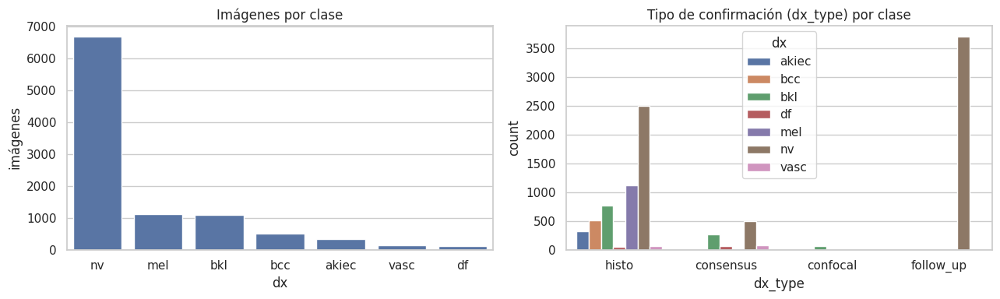

In [ ]:
print("Valores faltantes por columna:")
display(meta.isna().sum().to_frame("faltantes"))
print("Filas completamente duplicadas :", meta.duplicated().sum())
print("image_id duplicados            :", meta["image_id"].duplicated().sum())

cls = meta["dx"].value_counts().rename_axis("dx").reset_index(name="imágenes")
cls["%"] = (cls["imágenes"] / len(meta) * 100).round(2)
cls["nombre"] = cls["dx"].map(CLASS_NAMES_ES)
display(cls)
print(f"Razón de desbalance (clase mayoritaria / minoritaria): {cls['imágenes'].max() / cls['imágenes'].min():.1f} : 1")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.barplot(data=cls, x="dx", y="imágenes", order=cls["dx"], ax=ax[0], color="#4C72B0")
ax[0].set_title("Imágenes por clase")
sns.countplot(data=meta, x="dx_type", hue="dx", ax=ax[1], hue_order=CLASSES)
ax[1].set_title("Tipo de confirmación (dx_type) por clase")
plt.tight_layout(); plt.savefig(REPORTS / "fig_clases.png", dpi=130); plt.show()

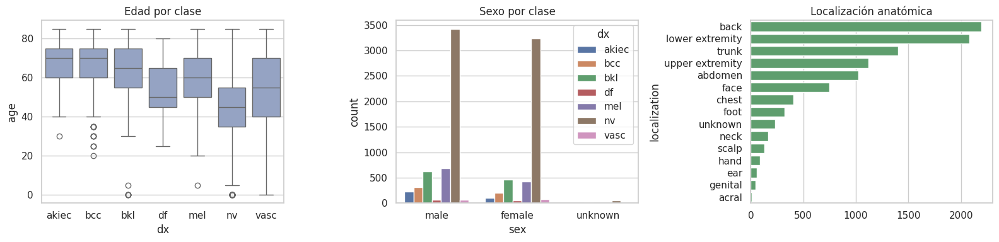

sex = unknown       : 57
localization unknown: 234
age faltante        : 57


In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.boxplot(data=meta, x="dx", y="age", order=CLASSES, ax=ax[0], color="#8DA0CB")
ax[0].set_title("Edad por clase")
sns.countplot(data=meta, x="sex", hue="dx", hue_order=CLASSES, ax=ax[1])
ax[1].set_title("Sexo por clase")
top_loc = meta["localization"].value_counts()
sns.barplot(x=top_loc.values, y=top_loc.index, ax=ax[2], color="#55A868")
ax[2].set_title("Localización anatómica")
plt.tight_layout(); plt.savefig(REPORTS / "fig_metadatos.png", dpi=130); plt.show()

print("sex = unknown       :", (meta["sex"] == "unknown").sum())
print("localization unknown:", (meta["localization"] == "unknown").sum())
print("age faltante        :", meta["age"].isna().sum())

## 3. Estructura por lesión

Una misma lesión (`lesion_id`) puede tener varias fotos. Si se divide el dataset al azar **por imagen**, fotos de la misma lesión caerían en entrenamiento y en prueba, y el modelo sería evaluado con casi las mismas imágenes con las que aprendió. Se mide aquí cuán grave sería, y la sección 9 lo evita agrupando por lesión.

Imágenes totales      : 10,015
Lesiones únicas       : 7,470
Lesiones con >1 foto  : 1,956  (26.2 % de las lesiones)
Imágenes que pertenecen a lesiones con >1 foto: 4,501 (44.9 %)
Lesiones con más de un dx distinto: 0

Con un split aleatorio por imagen, 981 lesiones quedarían repartidas entre varias particiones.


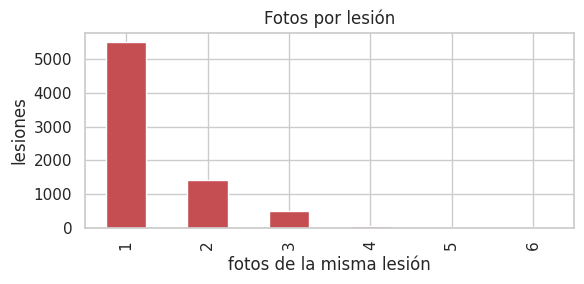

In [ ]:
per_lesion = meta.groupby("lesion_id").size()
multi = per_lesion[per_lesion > 1]
imgs_in_multi = int(per_lesion[per_lesion > 1].sum())
print(f"Imágenes totales      : {len(meta):,}")
print(f"Lesiones únicas       : {meta['lesion_id'].nunique():,}")
print(f"Lesiones con >1 foto  : {len(multi):,}  ({len(multi)/len(per_lesion)*100:.1f} % de las lesiones)")
print(f"Imágenes que pertenecen a lesiones con >1 foto: {imgs_in_multi:,} ({imgs_in_multi/len(meta)*100:.1f} %)")
print("Lesiones con más de un dx distinto:", int((meta.groupby('lesion_id')['dx'].nunique() > 1).sum()))

# Demostración: ¿cuánta fuga produciría un split aleatorio por imagen?
rng = np.random.default_rng(SEED)
naive = pd.Series(rng.choice(["train", "val", "test"], size=len(meta), p=[.7, .15, .15]), index=meta.index)
leak = (meta.assign(s=naive).groupby("lesion_id")["s"].nunique() > 1).sum()
print(f"\nCon un split aleatorio por imagen, {leak:,} lesiones quedarían repartidas entre varias particiones.")

per_lesion.value_counts().sort_index().plot(kind="bar", color="#C44E52", figsize=(6, 3),
                                            title="Fotos por lesión")
plt.xlabel("fotos de la misma lesión"); plt.ylabel("lesiones"); plt.tight_layout(); plt.show()

## 4. Inspección visual y validación de calidad

Se muestran ejemplos por clase y se **decodifican por completo** todas las imágenes (no solo se verifica el encabezado) para detectar archivos dañados y revisar las dimensiones.

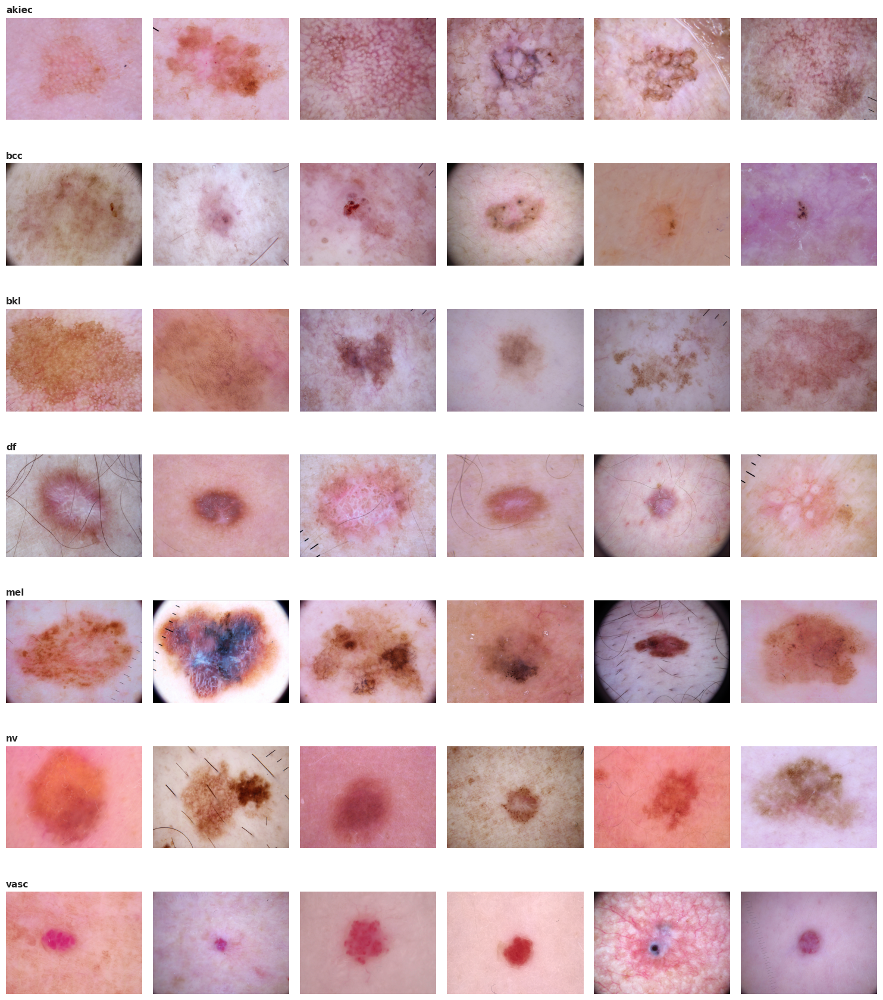

In [ ]:
fig, axes = plt.subplots(len(CLASSES), 6, figsize=(15, 2.5 * len(CLASSES)))
for r, c in enumerate(CLASSES):
    sub = meta[(meta["dx"] == c) & meta["image_path"].notna()].sample(6, random_state=SEED)
    for k, (_, row) in enumerate(sub.iterrows()):
        axes[r, k].imshow(read_rgb(row["image_path"])); axes[r, k].axis("off")
        if k == 0: axes[r, k].set_title(c, loc="left", fontsize=11, fontweight="bold")
plt.tight_layout(); plt.savefig(REPORTS / "fig_ejemplos_por_clase.png", dpi=110); plt.show()

In [ ]:
from concurrent.futures import ThreadPoolExecutor

def check_one(p):
    try:
        im = read_rgb(p)
        return {"image_id": Path(p).stem, "legible": True, "ancho": im.shape[1], "alto": im.shape[0]}
    except Exception as e:
        return {"image_id": Path(p).stem, "legible": False, "ancho": None, "alto": None}

paths = meta.loc[meta["image_path"].notna(), "image_path"].tolist()
with ThreadPoolExecutor(8) as ex:
    quality = pd.DataFrame(list(tqdm(ex.map(check_one, paths), total=len(paths), desc="Decodificando")))

print("Legibles   :", int(quality["legible"].sum()))
print("No legibles:", int((~quality["legible"]).sum()))
display(quality.groupby(["ancho", "alto"]).size().rename("imágenes").reset_index())
quality.to_csv(REPORTS / "calidad_imagenes.csv", index=False)

Decodificando:   0%|          | 0/10015 [00:00<?, ?it/s]

Legibles   : 10015
No legibles: 0


,ancho,alto,imágenes
0,600,450,10015


## 5. Pipeline de preprocesamiento: demostración paso a paso

Orden de las operaciones (el orden importa):

1. **Recorte de bordes negros** (viñeteado del dermatoscopio), *antes* de estimar el color para no sesgarlo.
2. **Eliminación de vello** (estilo DullRazor): *blackhat* morfológico → máscara → *inpainting*. Se hace a resolución original, donde el vello es más nítido. Si la máscara cubre más del 20 % de la imagen se omite, para no borrar la lesión.
3. **Constancia de color Shades of Gray** (p = 6): reduce las diferencias de iluminación y cámara entre imágenes.
4. **Cuadrado sin deformar + redimensión**: las originales son 600×450 (4:3). Antes se forzaba 224×224 aplastando la lesión; ahora se recorta el cuadrado central (o se rellena con negro con `square_mode="pad"`) y luego se redimensiona.

Se guardan a **256×256**; el redimensionado final a 224 se hace al cargar (aumento de datos).

Buscando vello real:   0%|          | 0/300 [00:00<?, ?it/s]

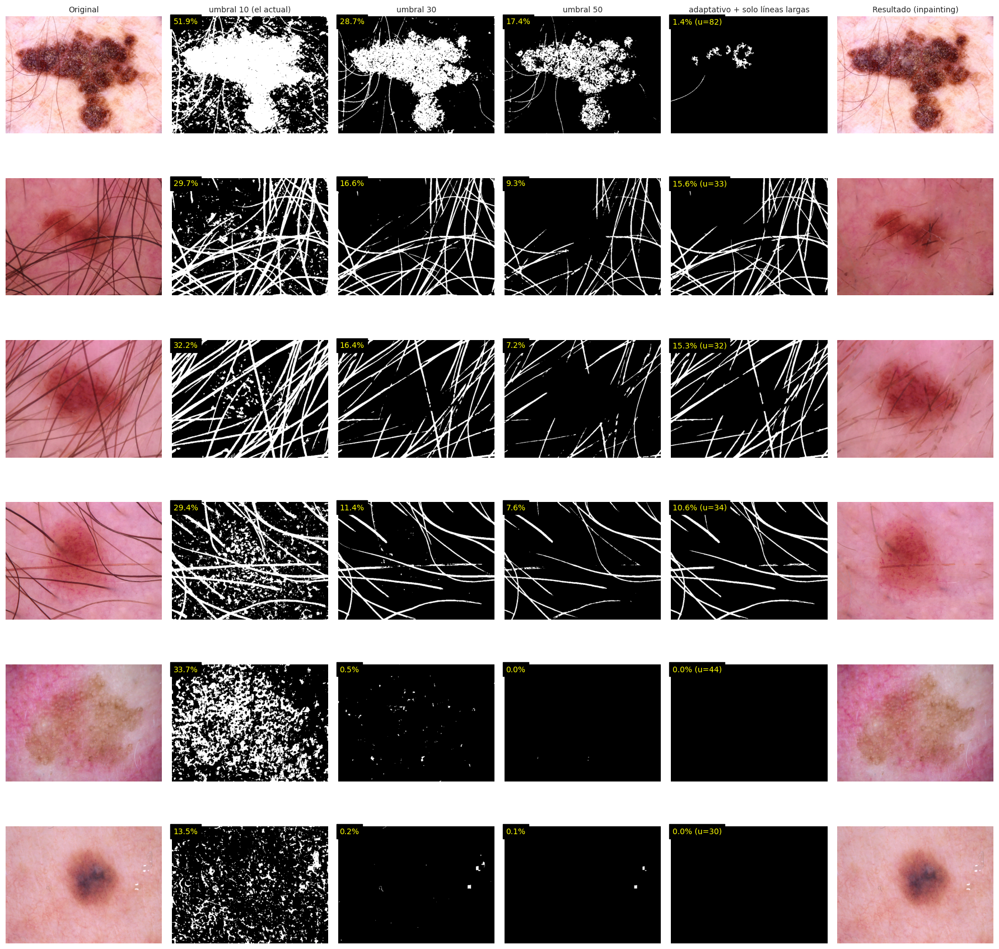

In [ ]:
# ---- CALIBRACIÓN DE LA MÁSCARA DE VELLO (reemplaza la celda de la demo de la sección 5) ----
def blackhat(img, kernel=17):
    g = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    se = cv2.getStructuringElement(cv2.MORPH_RECT, (kernel, kernel))
    return cv2.GaussianBlur(cv2.morphologyEx(g, cv2.MORPH_BLACKHAT, se), (3, 3), 0)

def keep_elongated(mask, min_len=35, min_area=40):
    # El vello son líneas largas y finas; la textura de la piel son manchas pequeñas.
    n, lab, st, _ = cv2.connectedComponentsWithStats(mask, connectivity=8)
    keep = np.zeros(n, bool)
    keep[1:] = ((st[1:, cv2.CC_STAT_AREA] >= min_area) &
                (np.maximum(st[1:, cv2.CC_STAT_WIDTH], st[1:, cv2.CC_STAT_HEIGHT]) >= min_len))
    return keep[lab].astype(np.uint8)

def adaptive_thr(bh, floor=30, k=6):
    # Umbral por imagen: el vello es un "valor atípico" respecto a la textura de fondo.
    med = np.median(bh); mad = np.median(np.abs(bh - med)) + 1e-6
    return max(floor, med + k * 1.4826 * mad)

# Elegir imágenes con vello OSCURO y LARGO (no por fracción de máscara, que era engañosa).
cand = meta[meta["image_path"].notna()].sample(300, random_state=SEED).copy()
scores = []
for p in tqdm(cand["image_path"], desc="Buscando vello real"):
    bh = blackhat(read_rgb(p))
    scores.append(float(keep_elongated((bh > 40).astype(np.uint8)).mean()))
cand["hair_score"] = scores
demo = pd.concat([cand.nlargest(4, "hair_score"), cand.nsmallest(2, "hair_score")])

cols = ["Original", "umbral 10 (el actual)", "umbral 30", "umbral 50",
        "adaptativo + solo líneas largas", "Resultado (inpainting)"]
fig, axes = plt.subplots(len(demo), 6, figsize=(18, 3 * len(demo)))
for r, (_, row) in enumerate(demo.iterrows()):
    img = read_rgb(row["image_path"]); bh = blackhat(img)
    t_ad = adaptive_thr(bh)
    m10, m30, m50 = [(bh > t).astype(np.uint8) for t in (10, 30, 50)]
    m_ad = keep_elongated((bh > t_ad).astype(np.uint8))
    m_ad_d = cv2.dilate(m_ad * 255, np.ones((3, 3), np.uint8))
    res = cv2.inpaint(img, m_ad_d, 3, cv2.INPAINT_TELEA) if m_ad.any() else img
    panels = [img, m10, m30, m50, m_ad, res]
    pcts = [None, m10.mean(), m30.mean(), m50.mean(), m_ad.mean(), None]
    for k, (im, pc) in enumerate(zip(panels, pcts)):
        axes[r, k].imshow(im, cmap="gray" if 1 <= k <= 4 else None); axes[r, k].axis("off")
        if r == 0: axes[r, k].set_title(cols[k], fontsize=10)
        if pc is not None:
            axes[r, k].text(5, 28, f"{pc*100:.1f}%" + (f" (u={t_ad:.0f})" if k == 4 else ""),
                            color="yellow", fontsize=10, backgroundcolor="black")
plt.tight_layout(); plt.savefig(REPORTS / "fig_calibracion_vello.png", dpi=110); plt.show()

In [ ]:
# ---- ALTERNATIVA: usar el método "adaptativo + solo líneas largas" (columna 5 de la calibración) ----
import importlib
import hamvc.preprocess as _pp

NEW_HAIR_MASK = '''def hair_mask(img: np.ndarray, kernel: int = 17, thr: int = 30,
              min_len: int = 35, min_area: int = 40) -> np.ndarray:
    """Máscara de vello: blackhat + umbral adaptativo (mínimo thr) + solo componentes largas."""
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    se = cv2.getStructuringElement(cv2.MORPH_RECT, (kernel, kernel))
    bh = cv2.GaussianBlur(cv2.morphologyEx(gray, cv2.MORPH_BLACKHAT, se), (3, 3), 0)
    med = float(np.median(bh))
    mad = float(np.median(np.abs(bh - med))) + 1e-6
    mask = (bh > max(thr, med + 6 * 1.4826 * mad)).astype(np.uint8)
    n, lab, st, _ = cv2.connectedComponentsWithStats(mask, connectivity=8)
    keep = np.zeros(n, bool)
    keep[1:] = ((st[1:, cv2.CC_STAT_AREA] >= min_area) &
                (np.maximum(st[1:, cv2.CC_STAT_WIDTH], st[1:, cv2.CC_STAT_HEIGHT]) >= min_len))
    return cv2.dilate(keep[lab].astype(np.uint8) * 255, np.ones((3, 3), np.uint8))
'''

src = Path(_pp.__file__).read_text(encoding="utf-8")
a, b = src.index("def hair_mask"), src.index("def remove_hair")
Path(_pp.__file__).write_text(src[:a] + NEW_HAIR_MASK + src[b:], encoding="utf-8")
importlib.invalidate_caches(); importlib.reload(_pp)
from hamvc.preprocess import hair_mask, remove_hair, run_preprocessing, crop_black_borders, shades_of_gray, to_square
CFG = PreprocConfig(hair_thr=30, hair_max_frac=0.30)
print("Método de vello aplicado: adaptativo + solo líneas largas | CFG:", CFG.hair_thr, CFG.hair_max_frac)

Método de vello aplicado: adaptativo + solo líneas largas | CFG: 30 0.3


Buscando bordes negros:   0%|          | 0/300 [00:00<?, ?it/s]

Imágenes de la muestra (300) con borde negro recortado: 0


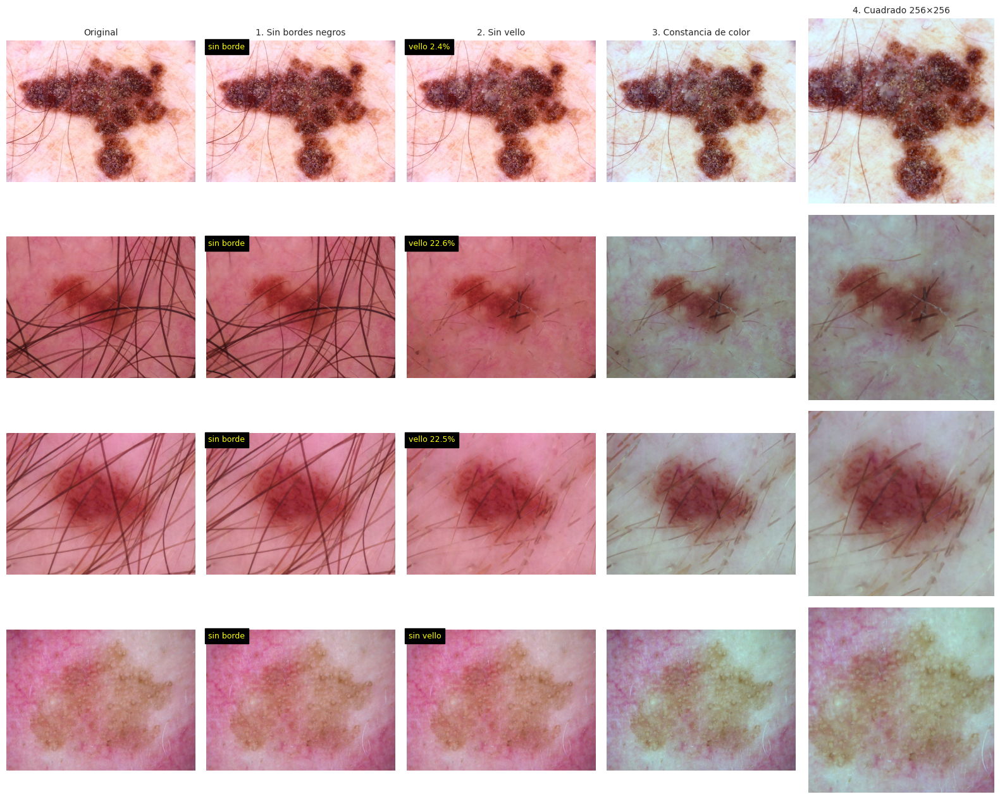

OK: la demo coincide con el pipeline real en todas las filas.


In [ ]:
  # ---- DEMO COMPLETA DEL PIPELINE (los 4 pasos), con el vello ya corregido ----
  from hamvc.preprocess import process_array

  # Imágenes: 3 con vello, hasta 2 con borde negro recortado y 1 sin vello
  cand["borde"] = [crop_black_borders(read_rgb(p), CFG.border_thr)[1]
                  for p in tqdm(cand["image_path"], desc="Buscando bordes negros")]
  con_borde = cand[cand["borde"]].head(2)
  demo2 = pd.concat([cand.nlargest(3, "hair_score"), con_borde,
                    cand[~cand.index.isin(con_borde.index)].nsmallest(1, "hair_score")]).drop_duplicates("image_id")
  print(f"Imágenes de la muestra (300) con borde negro recortado: {int(cand['borde'].sum())}")

  titles = ["Original", "1. Sin bordes negros", "2. Sin vello", "3. Constancia de color",
            f"4. Cuadrado {CFG.img_size}×{CFG.img_size}"]
  fig, axes = plt.subplots(len(demo2), 5, figsize=(16, 3.2 * len(demo2)))
  for r, (_, row) in enumerate(demo2.iterrows()):
      a = read_rgb(row["image_path"])
      b, cropped = crop_black_borders(a, CFG.border_thr)
      c, frac, applied = remove_hair(b, CFG.hair_kernel, CFG.hair_thr, CFG.hair_max_frac, CFG.inpaint_radius)
      d = shades_of_gray(c, CFG.sog_power)
      e = to_square(d, CFG.img_size, CFG.square_mode)
      # comprobación: la demo debe ser idéntica al pipeline real que se usa en la sección 6
      assert np.array_equal(e, process_array(a, CFG)[0]), "la demo no coincide con process_array"
      for k, im in enumerate([a, b, c, d, e]):
          axes[r, k].imshow(im); axes[r, k].axis("off")
          if r == 0: axes[r, k].set_title(titles[k], fontsize=10)
      axes[r, 1].text(5, 28, "recortado" if cropped else "sin borde", color="yellow", fontsize=9, backgroundcolor="black")
      axes[r, 2].text(5, 28, f"vello {frac*100:.1f}%" if applied else "sin vello", color="yellow", fontsize=9, backgroundcolor="black")
      axes[r, 0].set_ylabel(row["image_id"])
  plt.tight_layout(); plt.savefig(REPORTS / "fig_pipeline_pasos.png", dpi=110); plt.show()
  print("OK: la demo coincide con el pipeline real en todas las filas.")

## 6. Ejecución sobre todo el dataset

Se procesa en paralelo y es **reanudable**: cada resultado se anota en un `.jsonl`; si Colab se desconecta, al volver a ejecutar esta celda solo se procesan las imágenes pendientes. Por imagen también se guardan estadísticas (media/desviación por canal, brillo, nitidez, fracción de vello) y un hash perceptual.

In [ ]:
t0 = time.time()
stats = run_preprocessing(meta[meta["image_path"].notna()], PROC_DIR, CFG,
                          workers=os.cpu_count() or 2, log_path=WORK / "preproc_log.jsonl")
print(f"Tiempo: {(time.time()-t0)/60:.1f} min")
print("Procesadas OK:", int(stats["ok"].sum()), "| con error:", int((~stats["ok"]).sum()))
if (~stats["ok"]).any():
    display(stats.loc[~stats["ok"], ["image_id", "error"]])

Ya procesadas: 6,080 | pendientes: 3,935


Preprocesando:   0%|          | 0/3935 [00:00<?, ?it/s]

Tiempo: 3.7 min
Procesadas OK: 10015 | con error: 0


## 7. Resultados del preprocesamiento

Imágenes con recorte de bordes : 4 (0.0 %)
Imágenes con vello eliminado   : 3,787 (37.8 %)
Imágenes con vello omitido (>30%): 1,215


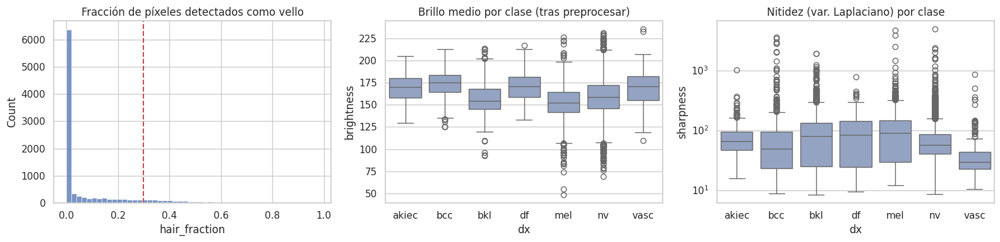

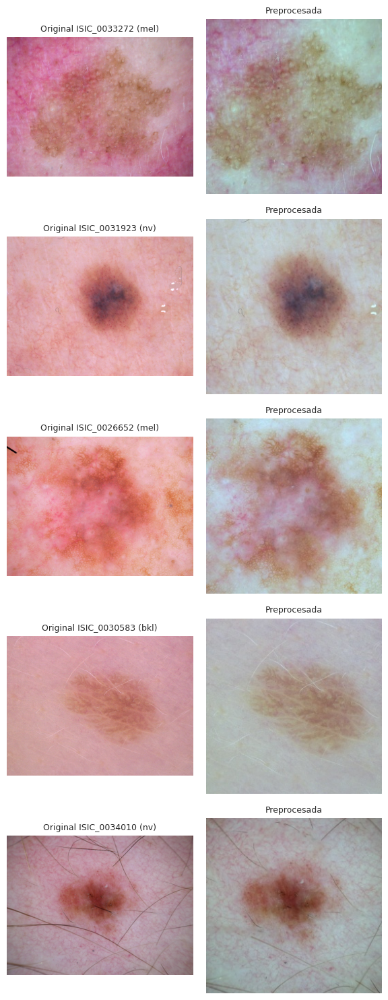

In [ ]:
ok = stats[stats["ok"]].drop(columns=["ok", "error"], errors="ignore")
proc = meta.merge(ok, on="image_id", how="inner").reset_index(drop=True)

print(f"Imágenes con recorte de bordes : {proc['border_cropped'].sum():,} ({proc['border_cropped'].mean()*100:.1f} %)")
print(f"Imágenes con vello eliminado   : {proc['hair_removed'].sum():,} ({proc['hair_removed'].mean()*100:.1f} %)")
print(f"Imágenes con vello omitido (>{CFG.hair_max_frac:.0%}): {((proc['hair_fraction'] > CFG.hair_max_frac)).sum():,}")

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(proc["hair_fraction"], bins=50, ax=ax[0]); ax[0].axvline(CFG.hair_max_frac, color="r", ls="--")
ax[0].set_title("Fracción de píxeles detectados como vello")
sns.boxplot(data=proc, x="dx", y="brightness", order=CLASSES, ax=ax[1], color="#8DA0CB")
ax[1].set_title("Brillo medio por clase (tras preprocesar)")
sns.boxplot(data=proc, x="dx", y="sharpness", order=CLASSES, ax=ax[2], color="#8DA0CB")
ax[2].set_yscale("log"); ax[2].set_title("Nitidez (var. Laplaciano) por clase")
plt.tight_layout(); plt.savefig(REPORTS / "fig_resultados_preproc.png", dpi=130); plt.show()

# Antes/después en muestras aleatorias
sample = proc.sample(5, random_state=SEED)
fig, axes = plt.subplots(5, 2, figsize=(6, 15))
for i, (_, r) in enumerate(sample.iterrows()):
    axes[i, 0].imshow(read_rgb(r["image_path"])); axes[i, 0].set_title(f"Original {r['image_id']} ({r['dx']})", fontsize=9)
    axes[i, 1].imshow(read_rgb(PROC_DIR / f"{r['image_id']}{CFG.out_ext}")); axes[i, 1].set_title("Preprocesada", fontsize=9)
    axes[i, 0].axis("off"); axes[i, 1].axis("off")
plt.tight_layout(); plt.savefig(REPORTS / "fig_antes_despues.png", dpi=110); plt.show()

## 8. Casi-duplicados y grupos

El SHA-256 solo detecta archivos idénticos byte a byte (casi nunca ocurre). Para detectar **la misma lesión fotografiada dos veces con distinto `lesion_id`** se usa un hash perceptual (pHash). Los pares con distancia de Hamming ≤ `NEAR_DUP_DIST` se tratan como el mismo grupo, junto con las imágenes de un mismo `lesion_id`. La partición de la sección 9 respeta estos grupos.

,0,1,2,3,4,5,6,7,8
umbral (≤),0,1,2,3,4,5,6,7,8
pares,9,9,83,83,327,327,1182,1182,3913


Pares casi-duplicados (dist ≤ 2): 83
  dentro de la misma lesión : 56
  entre lesiones distintas  : 27   <- fuga oculta si no se agrupan
  de ellos con dx distinto  : 2

lesion_id únicos: 7,470  ->  grupos finales: 7,448
Grupo más grande: 13 imágenes | grupos con más de 6 imágenes: 4


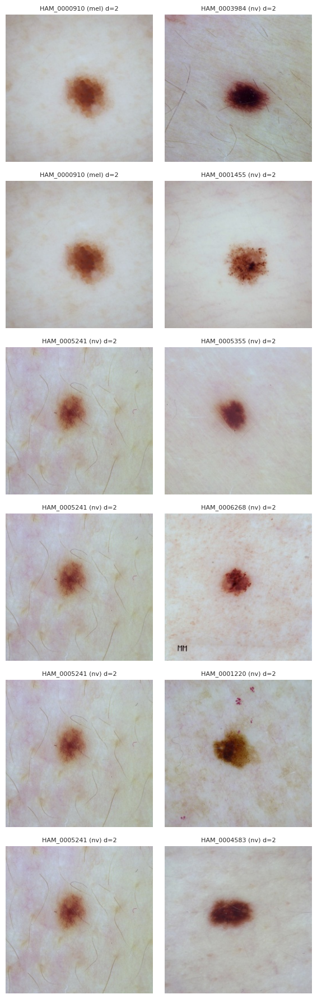

In [ ]:
pairs_all = near_duplicate_pairs(proc["phash"].tolist(), max_dist=8)
# Sensibilidad: las dermatoscopías se parecen mucho entre sí, así que un umbral laxo puede
# unir imágenes que NO son la misma foto. Esta tabla ayuda a elegir NEAR_DUP_DIST.
dist_all = pd.Series([d for _, _, d in pairs_all], dtype=int)
sens = pd.DataFrame({"umbral (≤)": range(0, 9),
                     "pares": [int((dist_all <= t).sum()) for t in range(0, 9)]})
display(sens.T)
pairs = [p for p in pairs_all if p[2] <= NEAR_DUP_DIST]
pd_ = pd.DataFrame(pairs, columns=["i", "j", "dist"])
pd_["lesion_i"] = proc.loc[pd_["i"], "lesion_id"].values
pd_["lesion_j"] = proc.loc[pd_["j"], "lesion_id"].values
pd_["dx_i"] = proc.loc[pd_["i"], "dx"].values
pd_["dx_j"] = proc.loc[pd_["j"], "dx"].values
cross = pd_[pd_["lesion_i"] != pd_["lesion_j"]]
print(f"Pares casi-duplicados (dist ≤ {NEAR_DUP_DIST}): {len(pd_):,}")
print(f"  dentro de la misma lesión : {len(pd_) - len(cross):,}")
print(f"  entre lesiones distintas  : {len(cross):,}   <- fuga oculta si no se agrupan")
print(f"  de ellos con dx distinto  : {(cross['dx_i'] != cross['dx_j']).sum():,}")

proc["group_id"] = build_groups(proc, pairs)
gsize = proc.groupby("group_id").size()
print(f"\nlesion_id únicos: {proc['lesion_id'].nunique():,}  ->  grupos finales: {proc['group_id'].nunique():,}")
print(f"Grupo más grande: {gsize.max()} imágenes | grupos con más de 6 imágenes: {(gsize > 6).sum()}")
if gsize.max() > 15:
    print("AVISO: hay grupos muy grandes; probablemente el umbral NEAR_DUP_DIST es demasiado laxo (falsos duplicados).")

# Verificación visual de pares entre lesiones distintas (conviene mirarlos antes de aceptar el umbral)
show = cross.sort_values("dist").head(6)
if len(show):
    fig, axes = plt.subplots(len(show), 2, figsize=(6, 3 * len(show)))
    axes = np.atleast_2d(axes)
    for r, (_, p) in enumerate(show.iterrows()):
        for k, idx in enumerate((p["i"], p["j"])):
            row = proc.loc[idx]
            axes[r, k].imshow(read_rgb(PROC_DIR / f"{row['image_id']}{CFG.out_ext}"))
            axes[r, k].set_title(f"{row['lesion_id']} ({row['dx']}) d={int(p['dist'])}", fontsize=8); axes[r, k].axis("off")
    plt.tight_layout(); plt.savefig(REPORTS / "fig_casi_duplicados.png", dpi=110); plt.show()

## 9. Partición train / val / test sin fuga de datos

`StratifiedGroupKFold`: **agrupa** por `group_id` (lesión + casi-duplicados) para que ningún grupo quede repartido, y **estratifica** por clase para que cada partición conserve la proporción de clases. Queda aprox. 69 % / 14 % / 17 %. Las comprobaciones son `assert`: si hay fuga, la celda falla.

split,train,val,test,total
dx,,,,
akiec,224,49,54,327
bcc,357,77,80,514
bkl,779,143,177,1099
df,80,15,20,115
mel,761,161,191,1113
nv,4675,913,1117,6705
vasc,102,17,23,142


split,train (%),val (%),test (%)
dx,,,
akiec,3.21,3.56,3.25
bcc,5.12,5.60,4.81
bkl,11.16,10.40,10.65
df,1.15,1.09,1.20
mel,10.91,11.71,11.49
nv,67.00,66.40,67.21
vasc,1.46,1.24,1.38


Tamaño de cada partición:


,imágenes
split,
train,6978
test,1662
val,1375


OK: ninguna lesión ni grupo aparece en más de una partición.


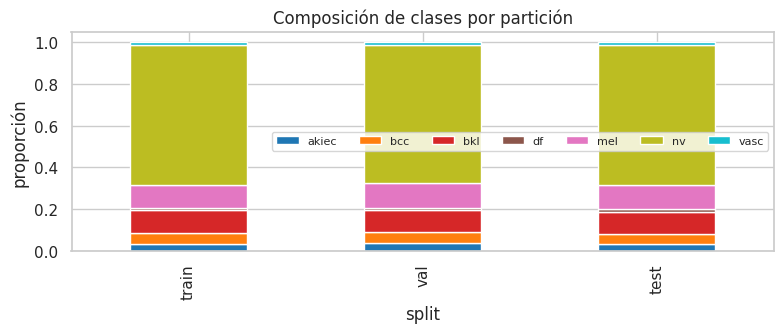

In [ ]:
proc["split"] = make_splits(proc, seed=SEED)
tab = check_splits(proc)          # lanza AssertionError si hay fuga o clases ausentes

summary = tab.copy()
summary["total"] = summary.sum(axis=1)
display(summary)
display((tab / tab.sum() * 100).round(2).add_suffix(" (%)"))
print("Tamaño de cada partición:"); display(proc["split"].value_counts().to_frame("imágenes"))
print("OK: ninguna lesión ni grupo aparece en más de una partición.")

fig, ax = plt.subplots(figsize=(8, 3.5))
(tab / tab.sum()).T.plot(kind="bar", stacked=True, ax=ax, colormap="tab10")
ax.set_ylabel("proporción"); ax.set_title("Composición de clases por partición"); ax.legend(ncol=7, fontsize=8)
plt.tight_layout(); plt.savefig(REPORTS / "fig_splits.png", dpi=130); plt.show()

## 10. Estadísticas de entrenamiento y manejo del desbalance

La normalización útil no es dividir entre 255 (siempre da 0–1), sino restar la **media** y dividir por la **desviación estándar por canal**, calculadas **solo con entrenamiento** para no filtrar información de val/test. Para el desbalance se calculan pesos por clase (para la función de pérdida) y se deja listo un muestreador balanceado; en la sección 11 se comprueba su efecto.

In [ ]:
train = proc[proc["split"] == "train"]
mean, std = channel_mean_std(train)
cw = class_weights(train["dx"])

print("Media RGB (train):", np.round(mean, 4))
print("Desv. RGB (train):", np.round(std, 4))
print("(referencia ImageNet: media [0.485 0.456 0.406], desv [0.229 0.224 0.225])")
display(pd.DataFrame(cw))

train_stats = {"mean": mean, "std": std, "class_order": CLASSES, "class_weights": cw,
               "n_train": int(len(train)), "img_size": CFG.img_size}
(REPORTS / "train_stats.json").write_text(json.dumps(train_stats, indent=2, ensure_ascii=False))

Media RGB (train): [0.6539 0.6137 0.6066]
Desv. RGB (train): [0.1123 0.1686 0.176 ]
(referencia ImageNet: media [0.485 0.456 0.406], desv [0.229 0.224 0.225])


,counts,inverse_frequency,effective_number
akiec,224,4.4503,0.9591
bcc,357,2.7923,0.6411
bkl,779,1.2797,0.3557
df,80,12.4607,2.5034
mel,761,1.3099,0.3613
nv,4675,0.2132,0.1944
vasc,102,9.7731,1.9849


854

## 11. Aumento de datos

Se define el pipeline de entrenamiento (volteos, rotaciones de 90°, ligera variación de color, redimensión a 224 y normalización con las estadísticas de train). **Solo se aplica a entrenamiento.** Abajo se visualiza y se comprueba el muestreador balanceado.

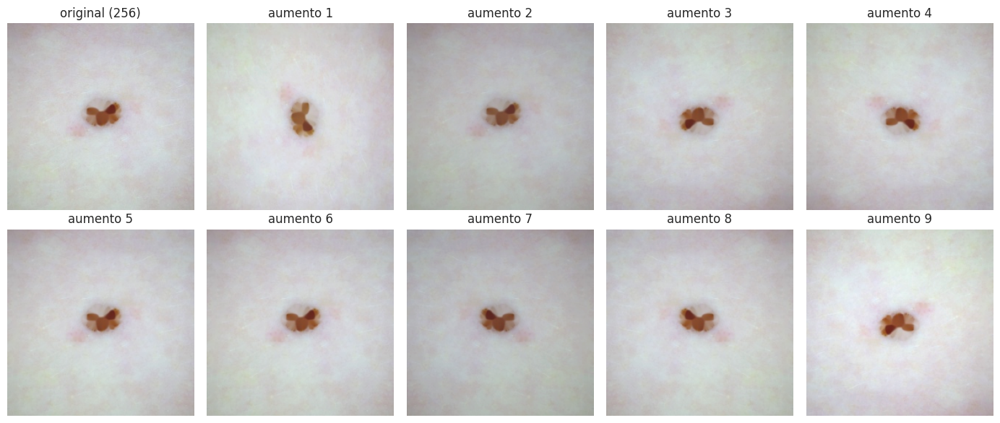

In [ ]:
from hamvc.augment import preview_transforms, train_transforms, eval_transforms

row = train[train["dx"] == "mel"].iloc[0]
img = read_rgb(PROC_DIR / f"{row['image_id']}{CFG.out_ext}")
tf = preview_transforms(224)
fig, axes = plt.subplots(2, 5, figsize=(14, 6))
axes[0, 0].imshow(img); axes[0, 0].set_title("original (256)")
for k, ax in enumerate(axes.flat[1:]):
    ax.imshow(tf(image=img)["image"]); ax.set_title(f"aumento {k+1}")
for ax in axes.flat: ax.axis("off")
plt.tight_layout(); plt.savefig(REPORTS / "fig_aumento.png", dpi=110); plt.show()

In [ ]:
try:
    import torch
    from torch.utils.data import DataLoader
    from hamvc.dataset import DermDataset, make_weighted_sampler

    ds = DermDataset(train, PROC_DIR, train_transforms(mean, std, 224), ext=CFG.out_ext)
    x, y = ds[0]
    print("Tensor de una muestra:", tuple(x.shape), x.dtype, "| etiqueta:", y, CLASSES[y])

    def batch_dist(loader, n_batches=20):
        c = np.zeros(len(CLASSES))
        for b, (_, yy) in zip(range(n_batches), loader):
            c += np.bincount(yy.numpy(), minlength=len(CLASSES))
        return pd.Series(c / c.sum() * 100, index=CLASSES).round(1)

    plain = DataLoader(ds, batch_size=64, shuffle=True, num_workers=2)
    bal = DataLoader(ds, batch_size=64, sampler=make_weighted_sampler(ds.labels), num_workers=2)
    display(pd.DataFrame({"sin balancear (%)": batch_dist(plain), "muestreo balanceado (%)": batch_dist(bal)}))
except ImportError:
    print("PyTorch no está instalado: se omite la comprobación del DataLoader.")

Tensor de una muestra: (3, 224, 224) torch.float32 | etiqueta: 2 bkl


,sin balancear (%),muestreo balanceado (%)
akiec,3.8,13.8
bcc,5.2,13.6
bkl,10.2,12.7
df,1.0,14.9
mel,10.2,14.4
nv,68.2,15.9
vasc,1.5,14.7


## 12. Exportación y resumen de la ejecución

Se guardan los CSV ligeros (los que sí conviene subir a GitHub) y las imágenes preprocesadas en un ZIP en tu Drive (**no** van a GitHub: HAM10000 se distribuye con licencia CC BY-NC 4.0 y son ~10 000 imágenes médicas).

In [ ]:
cols = ["image_id", "lesion_id", "group_id", "dx", "dx_type", "age", "sex", "localization", "split",
        "orig_w", "orig_h", "border_cropped", "hair_fraction", "hair_removed", "brightness", "sharpness",
        "mean_r", "mean_g", "mean_b", "meansq_r", "meansq_g", "meansq_b", "phash"]
proc[cols].to_csv(REPORTS / "splits_y_metadatos.csv", index=False)
pd_.to_csv(REPORTS / "pares_casi_duplicados.csv", index=False)
tab.to_csv(REPORTS / "clases_por_particion.csv")

run_summary = {
    "dataset_root": str(DATASET_ROOT),
    "config": CFG.__dict__,
    "near_dup_dist": NEAR_DUP_DIST,
    "inventario": inv,
    "imagenes_legibles": int(quality["legible"].sum()),
    "imagenes_preprocesadas": int(len(proc)),
    "errores_preprocesamiento": int((~stats["ok"]).sum()),
    "lesiones_unicas": int(proc["lesion_id"].nunique()),
    "grupos_finales": int(proc["group_id"].nunique()),
    "pares_casi_duplicados": int(len(pd_)),
    "pares_entre_lesiones_distintas": int(len(cross)),
    "tamano_particiones": proc["split"].value_counts().to_dict(),
    "imagenes_con_vello_eliminado": int(proc["hair_removed"].sum()),
    "imagenes_con_borde_recortado": int(proc["border_cropped"].sum()),
}
(REPORTS / "resumen_ejecucion.json").write_text(json.dumps(run_summary, indent=2, ensure_ascii=False, default=str))

# ZIP de imágenes + reportes -> Drive
zip_path = shutil.make_archive(str(WORK / "HAM10000_preprocesado"), "zip", root_dir=WORK,
                               base_dir="processed")
shutil.copy2(zip_path, EXPORT_DIR / "HAM10000_preprocesado.zip")
shutil.copytree(REPORTS, EXPORT_DIR / "reports", dirs_exist_ok=True)

print("Exportado en:", EXPORT_DIR)
print(f"ZIP: {Path(zip_path).stat().st_size/1e6:.0f} MB")
display(Markdown("### Resumen de la ejecución\n```json\n" +
                 json.dumps(run_summary, indent=2, ensure_ascii=False, default=str) + "\n```"))

Exportado en: /content/drive/MyDrive/HAM10000_procesado
ZIP: 191 MB


### Resumen de la ejecución
```json
{
  "dataset_root": "/content/drive/MyDrive/Proyecto_V-C_HAM10000",
  "config": {
    "img_size": 256,
    "square_mode": "center_crop",
    "crop_borders": true,
    "border_thr": 20,
    "remove_hair": true,
    "hair_kernel": 17,
    "hair_thr": 30,
    "hair_max_frac": 0.3,
    "inpaint_radius": 3,
    "color_constancy": true,
    "sog_power": 6,
    "out_ext": ".jpg",
    "jpg_quality": 95,
    "seed": 42
  },
  "near_dup_dist": 2,
  "inventario": {
    "archivos_de_imagen": 10016,
    "ids_unicos_en_archivos": 10016,
    "colisiones_de_nombre": 0,
    "filas_de_metadatos": 10015,
    "metadatos_con_imagen": 10015,
    "metadatos_sin_imagen": 0,
    "imagenes_sin_metadatos": 1
  },
  "imagenes_legibles": 10015,
  "imagenes_preprocesadas": 10015,
  "errores_preprocesamiento": 0,
  "lesiones_unicas": 7470,
  "grupos_finales": 7448,
  "pares_casi_duplicados": 83,
  "pares_entre_lesiones_distintas": 27,
  "tamano_particiones": {
    "train": 6978,
    "test": 1662,
    "val": 1375
  },
  "imagenes_con_vello_eliminado": 3787,
  "imagenes_con_borde_recortado": 4
}
```